# 09 · Band fit of the precursor of GRB 230307A

Sprint task 3: fit the Band function to the precursor spectrum from `08_precursor_spectrum.ipynb`,
first with n6 on its own and then with n6, n8, na and b1 together, and compare with
Dichiara et al. (2023), Table 2:

| | E_peak (keV) | α | β | C-stat / d.o.f. |
|---|---|---|---|---|
| Dichiara (RMfit) | 170.3 ± 4.7 | −0.63 ± 0.04 | −2.95 ± 0.09 | 563.1 / 480 |

The second half of the notebook explains why a fit done "out of the box" with GDT does **not**
reproduce these numbers, and what has to change. The fixes live in `spectral_fit_tools.py`.

**The Band function** (Band et al. 1993, GDT's `Band`, parametrised by E_peak):

$$N(E) = A \begin{cases} \left(\frac{E}{100\,\mathrm{keV}}\right)^{\alpha} \exp\!\left(-\frac{(2+\alpha)E}{E_\mathrm{peak}}\right) & E < \frac{(\alpha-\beta)E_\mathrm{peak}}{2+\alpha} \\ \left(\frac{(\alpha-\beta)E_\mathrm{peak}}{(2+\alpha)\,100\,\mathrm{keV}}\right)^{\alpha-\beta} e^{\beta-\alpha} \left(\frac{E}{100\,\mathrm{keV}}\right)^{\beta} & \text{otherwise} \end{cases}$$

A is the normalisation (ph cm⁻² s⁻¹ keV⁻¹). It is *not* the flux density at 100 keV, because the
exponential still acts there: N(100 keV) = A exp(−100(2 + α)/E_peak). α and β are the low- and high-energy
photon indices, and E_peak = (2 + α) E₀ the peak of the νFν spectrum.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import json
import warnings

from gdt.core.spectra.functions import Band
from gdt.core.spectra.fitting import SpectralFitterCstat, SpectralFitterPstat

from settings import (CODE_DIR, BURST_ID, SPECTRAL_DETECTORS, FIT_RANGE_NAI,
                      FIT_RANGE_BGO, FIGURE_DIR)
from spectral_fit_tools import (load_spectra, channel_mask, fit_model, cstat,
                                covariance, profile_error)

SPECTRUM_DIR = CODE_DIR / "spectra"
DICHIARA = {"Epeak": (170.3, 4.7), "alpha": (-0.63, 0.04), "beta": (-2.95, 0.09),
            "cstat": 563.1, "dof": 480}

phas, baks, rsps = load_spectra(SPECTRUM_DIR, BURST_ID, SPECTRAL_DETECTORS)
def fit_range(det):
    return FIT_RANGE_BGO if det.startswith("b") else FIT_RANGE_NAI
masks = [channel_mask(rsp, fit_range(det)) for rsp, det in zip(rsps, SPECTRAL_DETECTORS)]

for det, rsp, mask in zip(SPECTRAL_DETECTORS, rsps, masks):
    lo, hi = np.asarray(rsp.ebounds.low_edges()), np.asarray(rsp.ebounds.high_edges())
    print(f"{det}: {mask.sum()} channels, {lo[mask][0]:.1f}-{hi[mask][-1]:.0f} keV")
print(f"total {sum(m.sum() for m in masks)} channels -> {sum(m.sum() for m in masks) - 4} d.o.f. "
      f"for a 4-parameter model (Dichiara: {DICHIARA['dof']})")

n6: 122 channels, 7.3-907 keV
n8: 122 channels, 7.7-920 keV
na: 121 channels, 7.3-916 keV
b1: 123 channels, 172.7-40313 keV
total 488 channels -> 484 d.o.f. for a 4-parameter model (Dichiara: 480)


## Choices made for the fit

* **Statistic: C-stat with the background model taken as known.** In GDT this is
  `SpectralFitterPstat`, *not* `SpectralFitterCstat` (see below). PG-stat, which allows for the
  background model's error, gives the same parameters (notebook 11). The value quoted is −2 ln L
  relative to a perfect model, the scale RMfit and XSPEC print.
* **Energy ranges: NaI 8–900 keV, BGO 200 keV–40 MeV**, keeping every channel that overlaps the
  range. Dichiara don't give their ranges. These are common GBM choices, and with them the fit
  reproduces Dichiara's parameters, but they were partly chosen *because* of that, so they are my
  inference. They give 484 d.o.f., 4 more than Dichiara's 480, so the selection isn't identical to
  theirs. Notebook 11 finds 75 plausible cuts that give exactly 480; E_peak over those spans
  152–170 keV, so the cuts are a real systematic.
* **Responses**: the DRM covering the precursor in each `.rsp2` file (notebook 08).
* **Errors**: from the profile likelihood (the parameter is stepped and all others refitted until the
  C-stat rises by 1, the usual 68% rule for one parameter). The covariance errors are shown alongside,
  and notebook 11 checks both against simulated spectra.
* Every fit is started from several points and the best one kept.

In [2]:
def band_starts():
    # [A, Epeak, alpha, beta, Epiv]; GDT's default A is 0.01, the best fit here is ~1.6
    return [[0.01, 500.0, -0.5, -2.5, 100.0], [1.5, 170.0, -0.6, -2.9, 100.0],
            [0.5, 300.0, -1.0, -2.3, 100.0]]

def band_fit(det_idx):
    sub = lambda items: [items[i] for i in det_idx]
    band = Band()
    fitter = fit_model(sub(phas), sub(baks), sub(rsps), sub(masks), band, band_starts())
    cov_err = np.sqrt(np.diag(covariance(fitter)))
    prof = [profile_error(sub(phas), sub(baks), sub(rsps), sub(masks), band, fitter, i)
            for i in range(4)]
    return band, fitter, cov_err, prof

def report(title, fitter, cov_err, prof):
    names = ["A", "Epeak", "alpha", "beta"]
    print(f"{title}: C-stat {cstat(fitter):.1f} / {fitter.dof} d.o.f., converged: {fitter.success}")
    for i, name in enumerate(names):
        err = "  ".join("unconstrained" if np.isnan(e) else f"{sign}{e:.4f}"
                        for sign, e in zip("-+", prof[i]))
        print(f"  {name:6s} = {fitter.parameters[i]:9.4f}  {err}"
              f"  (covariance +/- {cov_err[i]:.4f})")

## n6 on its own

In [3]:
n6 = SPECTRAL_DETECTORS.index("n6")
band_n6, fit_n6, cov_n6, prof_n6 = band_fit([n6])
report("n6 alone", fit_n6, cov_n6, prof_n6)

n6 alone: C-stat 102.0 / 118 d.o.f., converged: True
  A      =    1.2684  -0.2386  +0.6750  (covariance +/- 0.2411)
  Epeak  =  160.0115  -17.5190  +15.9948  (covariance +/- 11.9743)
  alpha  =   -1.0691  -0.2940  +0.5069  (covariance +/- 0.2702)
  beta   =   -3.1994  unconstrained  +0.5114  (covariance +/- 0.2965)


n6 on its own gives a softer low-energy index and a lower E_peak than the joint fit, with much
larger errors (the lower error on β is unconstrained: β can go as steep as GDT's −10 limit without
the C-stat rising by 1). That is expected: n6 has very little effective area below ~40 keV (notebook 08), so
it barely constrains α, and with no BGO there is little leverage on β either. E_peak and α are
strongly correlated in the Band function (a softer α can be traded for a lower E_peak), so the two
move together.

## n6, n8, na and b1 together

In [4]:
all_idx = list(range(len(SPECTRAL_DETECTORS)))
band_all, fit_all, cov_all, prof_all = band_fit(all_idx)
report("n6+n8+na+b1", fit_all, cov_all, prof_all)

print()
print(f"{'':8s}{'this work':>22s}{'Dichiara':>18s}{'difference / sigma':>22s}")
for i, name in [(1, "Epeak"), (2, "alpha"), (3, "beta")]:
    value, err = fit_all.parameters[i], np.mean(prof_all[i])
    d_value, d_err = DICHIARA[name]
    print(f"{name:8s}{value:12.2f} +/- {err:6.2f}{d_value:10.2f} +/- {d_err:5.2f}"
          f"{(value - d_value) / np.hypot(err, d_err):14.2f}")
print(f"{'C-stat':8s}{cstat(fit_all):12.1f} / {fit_all.dof}{DICHIARA['cstat']:12.1f} / {DICHIARA['dof']}")

n6+n8+na+b1: C-stat 568.7 / 484 d.o.f., converged: True
  A      =    1.6306  -0.0965  +0.1082  (covariance +/- 0.1013)
  Epeak  =  170.2679  -5.2786  +5.3440  (covariance +/- 5.2549)
  alpha  =   -0.6332  -0.0431  +0.0448  (covariance +/- 0.0437)
  beta   =   -2.9534  -0.1034  +0.0910  (covariance +/- 0.0946)

                     this work          Dichiara    difference / sigma
Epeak         170.27 +/-   5.31    170.30 +/-  4.70         -0.00
alpha          -0.63 +/-   0.04     -0.63 +/-  0.04         -0.05
beta           -2.95 +/-   0.10     -2.95 +/-  0.09         -0.03
C-stat         568.7 / 484       563.1 / 480


The joint fit reproduces Dichiara's Band parameters and errors. The C-stat is 5.6 higher for 4 more
channels, consistent with a slightly different channel selection.

## What changes the result compared with GDT's defaults

Each line below changes one thing from the fit above, to show which choices matter.

In [5]:
def joint_fit(fitter_class=SpectralFitterPstat, starts=None, ranges=None, method="SLSQP"):
    band = Band()
    m = masks if ranges is None else [channel_mask(r, ranges[1] if d.startswith("b") else ranges[0])
                                      for r, d in zip(rsps, SPECTRAL_DETECTORS)]
    best = None
    for start in (starts or band_starts()):
        f = fitter_class(phas, baks, rsps, channel_masks=m, method=method)
        band.default_values = list(start)
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            f.fit(band, options={"maxiter": 2000})
        if best is None or f.statistic < best.statistic:
            best = f
    return best

def line(label, f):
    p = f.parameters
    print(f"{label:52s} Epeak {p[1]:6.1f}  alpha {p[2]:6.3f}  beta {p[3]:6.2f}  "
          f"C-stat {cstat(f):7.1f}/{f.dof}  converged {f.success}")

line("reference (this notebook)", fit_all)
# 1. GDT's SpectralFitterCstat is XSPEC's W-stat: background treated as a Poisson measurement
#    with the same 0.38 s exposure as the source, instead of a well-known polynomial model
line("1. SpectralFitterCstat instead of Pstat", joint_fit(SpectralFitterCstat))
# 2. From GDT's default start (A = 0.01) the 'TNC' minimiser stops early, not converged
line("2. GDT default start values, TNC minimiser", joint_fit(starts=[Band().default_values], method="TNC"))
# 3. BGO starting at 250 or 300 keV instead of 200 keV
line("3a. BGO from 250 keV", joint_fit(ranges=(FIT_RANGE_NAI, (250.0, 40000.0))))
line("3b. BGO from 300 keV", joint_fit(ranges=(FIT_RANGE_NAI, (300.0, 40000.0))))
line("3c. NaI to 1000 keV", joint_fit(ranges=((8.0, 1000.0), FIT_RANGE_BGO)))

reference (this notebook)                            Epeak  170.3  alpha -0.633  beta  -2.95  C-stat   568.7/484  converged True


1. SpectralFitterCstat instead of Pstat              Epeak  172.9  alpha -0.647  beta  -3.15  C-stat   460.8/484  converged True


2. GDT default start values, TNC minimiser           Epeak  193.9  alpha -0.798  beta  -3.42  C-stat   588.2/484  converged False


3a. BGO from 250 keV                                 Epeak  165.4  alpha -0.621  beta  -2.88  C-stat   553.7/482  converged True


3b. BGO from 300 keV                                 Epeak  157.0  alpha -0.570  beta  -2.79  C-stat   545.6/481  converged True


3c. NaI to 1000 keV                                  Epeak  170.0  alpha -0.632  beta  -2.94  C-stat   580.0/491  converged True


4. **The statistic value.** GDT's `fitter.statistic` is −ln L, so it has to be doubled to compare with
   the C-stat printed by RMfit/XSPEC (Dichiara's 563.1). Undoubled, it looks like a fit that is
   "too good" (χ²/dof ≈ 0.6).

5. **The errors.** Here GDT's `symmetric_errors` came out ~5× smaller than both my covariance
   matrix and the profile likelihood. The diagonal of GDT's Hessian agrees with mine; the
   off-diagonal terms (the correlations between A, E_peak and α) don't. Notebook 11 tests why on a toy
   function with a known Hessian, and checks all the error estimates against simulated spectra. GDT's
   `asymmetric_errors` (in 2.2.3) uses Δ(−2 ln L) = χ²(68%, 4 parameters) = 4.7 and does not refit
   the other parameters, so it isn't the one-parameter profile error either. The cell below compares
   the three.

In [6]:
gdt_sym = fit_all.symmetric_errors
for i, name in [(1, "Epeak"), (2, "alpha"), (3, "beta")]:
    print(f"{name:6s} GDT symmetric_errors {gdt_sym[i]:7.3f}   own covariance {cov_all[i]:7.3f}   "
          f"profile -{prof_all[i][0]:.3f} +{prof_all[i][1]:.3f}   Dichiara {DICHIARA[name][1]}")

Epeak  GDT symmetric_errors   1.044   own covariance   5.255   profile -5.279 +5.344   Dichiara 4.7
alpha  GDT symmetric_errors   0.014   own covariance   0.044   profile -0.043 +0.045   Dichiara 0.04
beta   GDT symmetric_errors   0.022   own covariance   0.095   profile -0.103 +0.091   Dichiara 0.09


## Energy-range scan

How the result depends on the energy ranges, since the paper doesn't give them. The BGO lower edge
matters most: the BGO channels between 200 and 300 keV sit right around E_peak, and dropping them lets
the fit slide to a lower E_peak with a harder α. The NaI upper edge hardly matters.

NaI 8-900, BGO 150-40000 keV: Epeak  170.7  alpha -0.626  beta -2.97  C-stat  571.8/485


NaI 8-900, BGO 200-40000 keV: Epeak  170.3  alpha -0.633  beta -2.95  C-stat  568.7/484


NaI 8-900, BGO 250-40000 keV: Epeak  165.4  alpha -0.621  beta -2.88  C-stat  553.7/482


NaI 8-900, BGO 300-40000 keV: Epeak  157.0  alpha -0.570  beta -2.79  C-stat  545.6/481


NaI 8-1000, BGO 150-40000 keV: Epeak  170.5  alpha -0.625  beta -2.96  C-stat  583.2/492


NaI 8-1000, BGO 200-40000 keV: Epeak  170.0  alpha -0.632  beta -2.94  C-stat  580.0/491


NaI 8-1000, BGO 250-40000 keV: Epeak  165.1  alpha -0.619  beta -2.87  C-stat  565.0/489


NaI 8-1000, BGO 300-40000 keV: Epeak  156.8  alpha -0.569  beta -2.79  C-stat  556.8/488


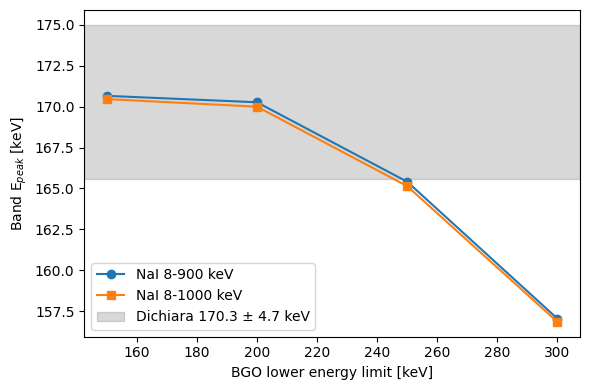

In [7]:
scan = []
for nai_hi in (900.0, 1000.0):
    for bgo_lo in (150.0, 200.0, 250.0, 300.0):
        f = joint_fit(ranges=((8.0, nai_hi), (bgo_lo, 40000.0)))
        scan.append((nai_hi, bgo_lo, *f.parameters[1:4], cstat(f), f.dof))
        print(f"NaI 8-{nai_hi:.0f}, BGO {bgo_lo:.0f}-40000 keV: Epeak {f.parameters[1]:6.1f}  "
              f"alpha {f.parameters[2]:6.3f}  beta {f.parameters[3]:5.2f}  "
              f"C-stat {cstat(f):6.1f}/{f.dof}")

fig, ax = plt.subplots(figsize=(6, 4))
for nai_hi, marker in ((900.0, "o"), (1000.0, "s")):
    rows = [r for r in scan if r[0] == nai_hi]
    ax.plot([r[1] for r in rows], [r[2] for r in rows], marker=marker, label=f"NaI 8-{nai_hi:.0f} keV")
ax.axhspan(DICHIARA["Epeak"][0] - DICHIARA["Epeak"][1], DICHIARA["Epeak"][0] + DICHIARA["Epeak"][1],
           color="grey", alpha=0.3, label="Dichiara 170.3 ± 4.7 keV")
ax.set_xlabel("BGO lower energy limit [keV]")
ax.set_ylabel("Band E$_{peak}$ [keV]")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURE_DIR / "09_energy_range_scan.png", dpi=200)
plt.show()

## Save the result

The best-fit parameters and errors go to `spectra/precursor_band_fit.json` so notebook 10 can check
it gets the same fit.

In [8]:
names = ["A", "Epeak", "alpha", "beta"]
result = {
    "detectors": SPECTRAL_DETECTORS, "fit_range_nai": FIT_RANGE_NAI, "fit_range_bgo": FIT_RANGE_BGO,
    "statistic": "C-stat, background model known (GDT SpectralFitterPstat)",
    "cstat": cstat(fit_all), "dof": int(fit_all.dof),
    "parameters": {n: float(v) for n, v in zip(names, fit_all.parameters)},
    "profile_errors": {n: [float(e) for e in prof_all[i]] for i, n in enumerate(names)},
    "covariance": covariance(fit_all).tolist(),
    "n6_alone": {"parameters": {n: float(v) for n, v in zip(names, fit_n6.parameters)},
                 "profile_errors": {n: [float(e) for e in prof_n6[i]] for i, n in enumerate(names)},
                 "cstat": cstat(fit_n6), "dof": int(fit_n6.dof)},
}
with open(SPECTRUM_DIR / "precursor_band_fit.json", "w") as f:
    json.dump(result, f, indent=2)
print(json.dumps(result["parameters"], indent=2))

{
  "A": 1.6305519092402034,
  "Epeak": 170.26785361419383,
  "alpha": -0.6331870411339083,
  "beta": -2.953379395088409
}
